# Step 3 – Explainability: Which factors drive bird species richness in Sri Lanka?
**Student:** Indrajith KTN 224078X

**AI use declaration:** This notebook's code was generated with the help of Claude (Anthropic)
and reviewed / run by the me.

Methods used: (1) built-in feature importance (Random Forest, XGBoost),
(2) permutation importance (model-agnostic), (3) SHAP values (XGBoost).



In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

c:\Users\nirmani\Desktop\SriLanka_Bird_Ensemble_Project\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Rebuild the same train/test data used in Step 1

In [3]:
DATA_PATH = "../data/processed/bird_monthly_data.csv"
if not os.path.exists(DATA_PATH):
    DATA_PATH = "bird_monthly_data.csv"
monthly_data = pd.read_csv(DATA_PATH)

def sl_season(m):
    if m in [12, 1, 2]:      return "NE_Monsoon"
    if m in [3, 4]:          return "Inter_Monsoon_1"
    if m in [5, 6, 7, 8, 9]: return "SW_Monsoon"
    return "Inter_Monsoon_2"

monthly_data["Season"] = monthly_data["Month"].apply(sl_season)
monthly_data = monthly_data.sort_values(["Year", "Month"]).reset_index(drop=True)

base_features = ["stateProvince", "Season", "Year", "Month",
                 "average_temperature", "average_rainfall", "average_humidity",
                 "average_ndvi", "average_wind", "average_elevation",
                 "average_population_density", "average_night_light"]

train_data = monthly_data[monthly_data["Year"] < 2023]
test_data  = monthly_data[monthly_data["Year"] >= 2023]

feature_columns = joblib.load("../models/feature_columns.pkl")
X_train = pd.get_dummies(train_data[base_features], columns=["stateProvince", "Season"]).reindex(columns=feature_columns, fill_value=0)
X_test  = pd.get_dummies(test_data[base_features],  columns=["stateProvince", "Season"]).reindex(columns=feature_columns, fill_value=0)
y_train, y_test = train_data["species_richness"], test_data["species_richness"]
print(X_train.shape, X_test.shape)

(1915, 39) (539, 39)


## 2. Load the trained models
`Random Forest` and `XGBoost` were saved as RandomizedSearchCV objects, so we take `.best_estimator_`.

In [4]:
rf_model  = joblib.load("../models/Random_Forest.pkl")
xgb_model = joblib.load("../models/XGBoost.pkl")
rf_best  = rf_model.best_estimator_  if hasattr(rf_model,  "best_estimator_") else rf_model
xgb_best = xgb_model.best_estimator_ if hasattr(xgb_model, "best_estimator_") else xgb_model

## 3. Grouped feature importance
Dummy columns (one per district / season) are combined back into "District" and "Season"
so the chart is easy to read.

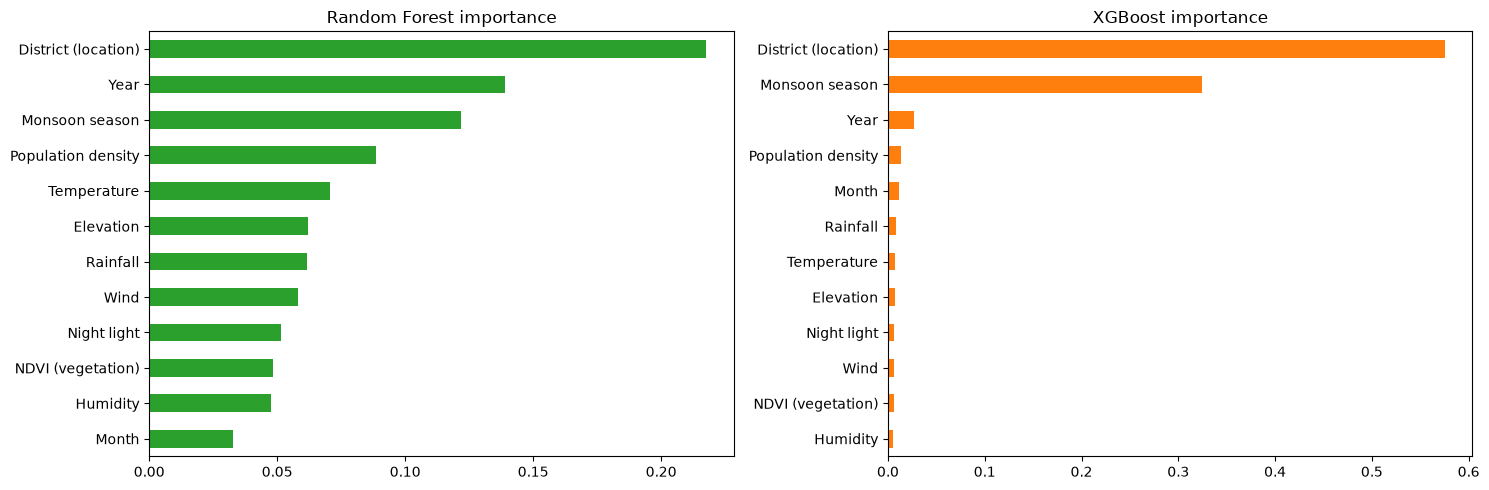

In [5]:
def group_name(col):
    if col.startswith("stateProvince_"): return "District (location)"
    if col.startswith("Season_"):        return "Monsoon season"
    return col

pretty = {"average_temperature": "Temperature", "average_rainfall": "Rainfall", "average_humidity": "Humidity",
          "average_ndvi": "NDVI (vegetation)", "average_wind": "Wind", "average_elevation": "Elevation",
          "average_population_density": "Population density", "average_night_light": "Night light",
          "Year": "Year", "Month": "Month"}

def grouped(values, cols):
    s = pd.Series(values, index=cols)
    s = s.groupby([group_name(c) for c in cols]).sum()
    s.index = [pretty.get(i, i) for i in s.index]
    return s.sort_values()

imp_rf  = grouped(rf_best.feature_importances_,  X_train.columns)
imp_xgb = grouped(xgb_best.feature_importances_, X_train.columns)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
imp_rf.plot.barh(ax=axes[0], color="tab:green");  axes[0].set_title("Random Forest importance")
imp_xgb.plot.barh(ax=axes[1], color="tab:orange"); axes[1].set_title("XGBoost importance")
plt.tight_layout(); plt.show()

## 4. Permutation importance (on the test set)
How much does the error get worse when one feature is shuffled? Works for any model and
is more reliable than built-in importance.

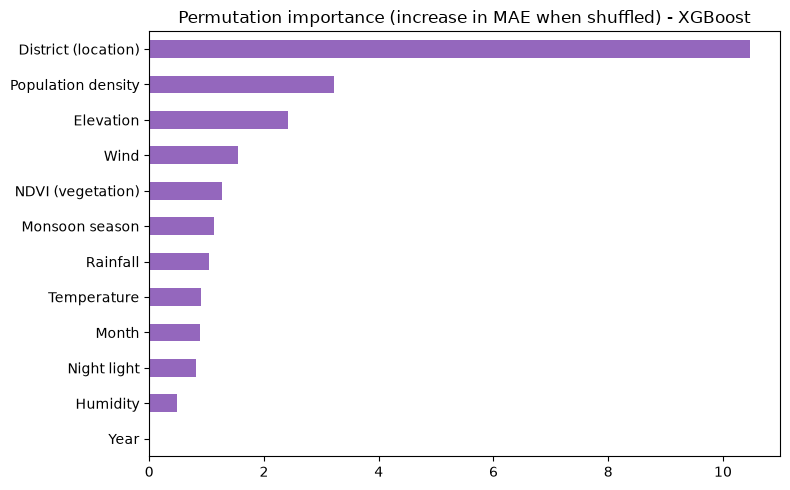

In [6]:
perm = permutation_importance(xgb_best, X_test, y_test, n_repeats=15, random_state=RANDOM_STATE,
                              scoring="neg_mean_absolute_error", n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=X_test.columns)
perm_g = perm_s.groupby([group_name(c) for c in X_test.columns]).sum()
perm_g.index = [pretty.get(i, i) for i in perm_g.index]
perm_g = perm_g.sort_values()

perm_g.plot.barh(figsize=(8, 5), color="tab:purple",
                 title="Permutation importance (increase in MAE when shuffled) - XGBoost")
plt.tight_layout(); plt.show()

## 5. SHAP (XGBoost)
SHAP shows *how* each feature pushes the prediction up or down.
Each dot = one test row; red = high feature value, blue = low.

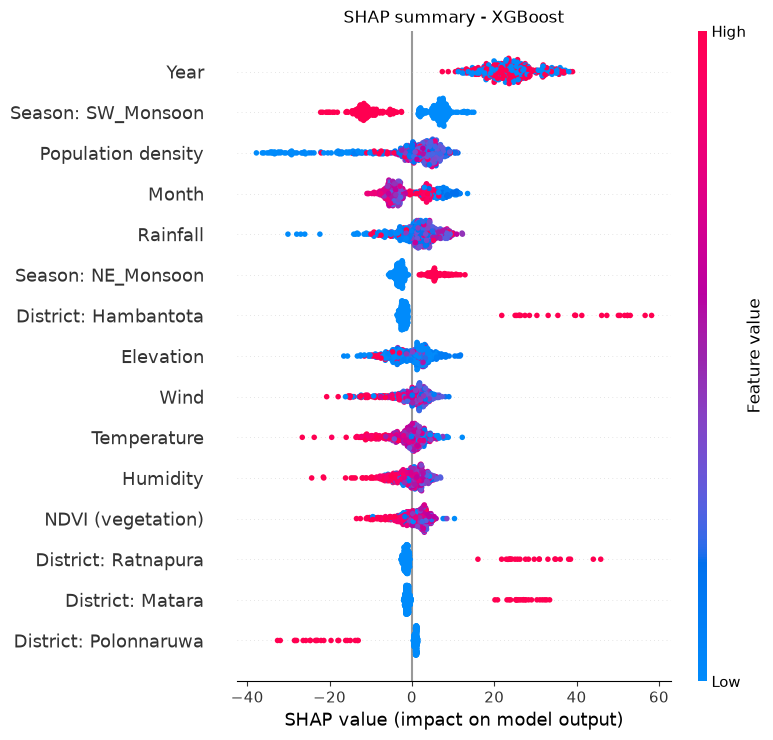

In [7]:
explainer = shap.TreeExplainer(xgb_best)
shap_values = explainer.shap_values(X_test)

# rename dummy columns for the plot
X_test_pretty = X_test.rename(columns=lambda c: pretty.get(c, c.replace("stateProvince_", "District: ").replace("Season_", "Season: ")))
shap.summary_plot(shap_values, X_test_pretty, max_display=15, show=False)
plt.title("SHAP summary - XGBoost")
plt.tight_layout()
os.makedirs("../data/processed", exist_ok=True)
plt.savefig("../data/processed/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

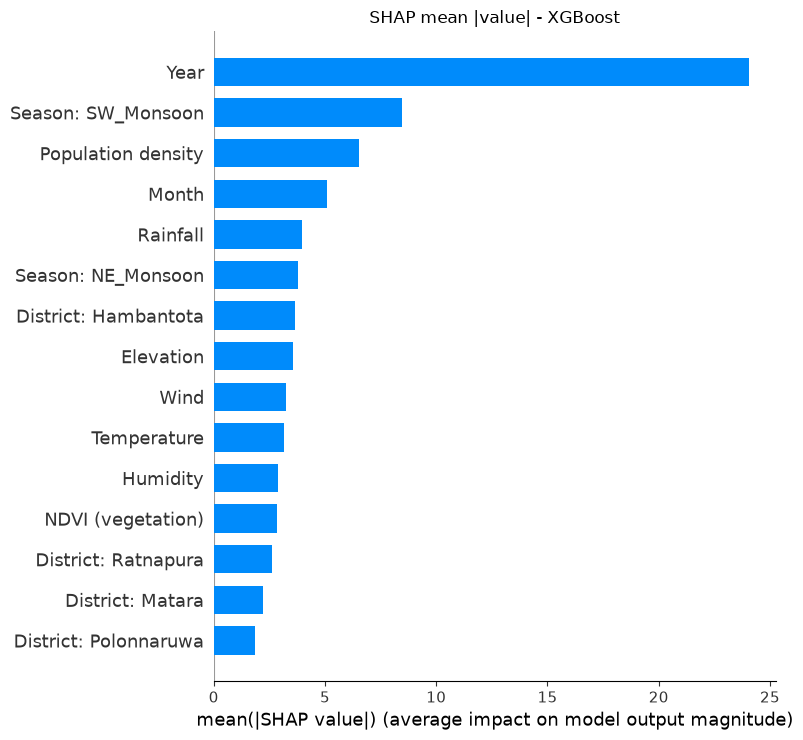

In [8]:
shap.summary_plot(shap_values, X_test_pretty, plot_type="bar", max_display=15, show=False)
plt.title("SHAP mean |value| - XGBoost")
plt.tight_layout(); plt.show()

## 6. Effect of one feature (partial dependence style)
Rainfall and NDVI vs their SHAP value.

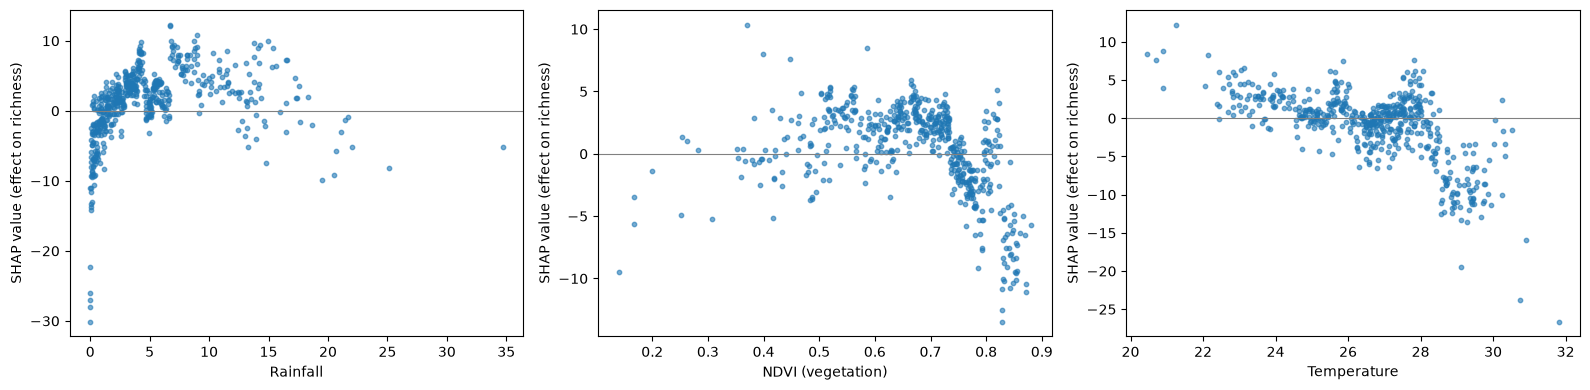

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["average_rainfall", "average_ndvi", "average_temperature"]):
    ax.scatter(X_test[col], shap_values[:, list(X_test.columns).index(col)], s=10, alpha=0.6)
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_xlabel(pretty[col]); ax.set_ylabel("SHAP value (effect on richness)")
plt.tight_layout(); plt.show()

## 7. What if survey effort (`observation_count`) is included?
This shows why the R² jumped from about 0.33 to 0.91 in Step 1.

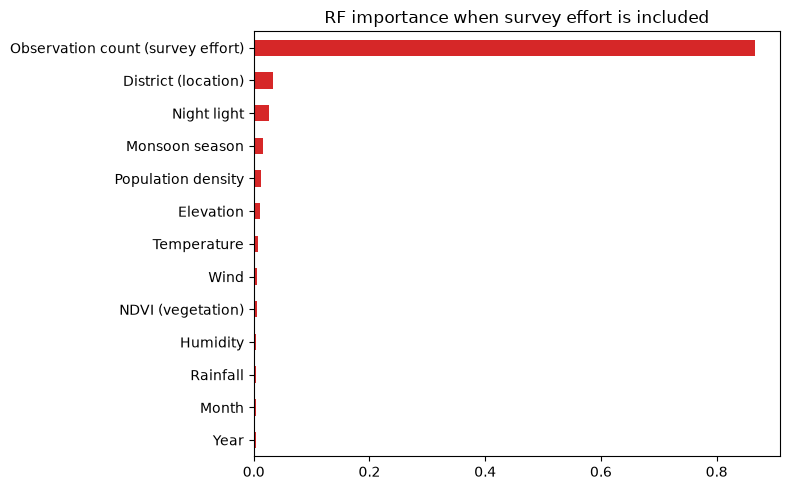

In [10]:
cols_eff = base_features + ["observation_count"]
Xtr_e = pd.get_dummies(train_data[cols_eff], columns=["stateProvince", "Season"])
Xte_e = pd.get_dummies(test_data[cols_eff],  columns=["stateProvince", "Season"]).reindex(columns=Xtr_e.columns, fill_value=0)
rf_eff = RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1).fit(Xtr_e, y_train)

imp_eff = grouped(rf_eff.feature_importances_, Xtr_e.columns).rename(index={"observation_count": "Observation count (survey effort)"})
imp_eff.plot.barh(figsize=(8, 5), color="tab:red", title="RF importance when survey effort is included")
plt.tight_layout(); plt.show()

## 8. Save importance table (for the dashboard)

In [11]:
imp_table = pd.DataFrame({"RandomForest": imp_rf, "XGBoost": imp_xgb, "Permutation_MAE": perm_g}).fillna(0)
imp_table = imp_table.sort_values("XGBoost", ascending=False)
imp_table.index.name = "Feature"
imp_table.to_csv("../data/processed/feature_importance.csv")
print("Saved: feature_importance.csv, shap_summary.png")
imp_table.round(4)

Saved: feature_importance.csv, shap_summary.png


,RandomForest,XGBoost,Permutation_MAE
Feature,,,
District (location),0.2175,0.5752,10.4702
Monsoon season,0.1217,0.3249,1.1353
Year,0.1392,0.0273,0.0000
Population density,0.0885,0.0134,3.2180
Month,0.0327,0.0119,0.8802
Rainfall,0.0618,0.0082,1.0415
Temperature,0.0708,0.0076,0.9049
Elevation,0.0620,0.0072,2.4153
Night light,0.0515,0.0066,0.8136


## 9. Interpretation

**Main finding:** District (location) is the strongest driver of recorded species richness
in both Random Forest (importance about 0.22) and XGBoost (about 0.58). Monsoon season is
second in XGBoost (about 0.33). Climate variables (temperature, rainfall, humidity, NDVI, wind)
each add only a small amount on their own.

- **District:** Districts differ in habitat (for example Sinharaja rainforest in Ratnapura and the
  coastal wetlands of Bundala in Hambantota) and in how many birdwatchers visit them. In the SHAP plot,
  Hambantota, Ratnapura and Matara push the predicted richness up strongly (roughly +20 to +55 species),
  while Polonnaruwa pushes it down (roughly -10 to -30).
- **Monsoon season:** The North-East monsoon (Dec-Feb) raises the prediction (roughly +5 to +10), and the
  South-West monsoon (May-Sep) lowers it (roughly -10 to -25). This fits the migratory bird season in
  Sri Lanka (Oct-Mar) and the fact that birdwatching is more active in drier months.
- **Year:** Year gives a positive shift for all 2023-2024 test rows. This suggests more species were
  recorded in recent years, probably because more people and apps now record birds (citizen science),
  not necessarily because biodiversity increased. Year looks small in XGBoost's built-in importance but
  large in SHAP, because SHAP measures the actual shift in predictions for the test years.
- **Population density:** Low density lowers the prediction and high density raises it. Populated areas
  have more observers, so more records.
- **Rainfall, temperature, humidity, wind, NDVI:** Their effects are small and mixed. High humidity,
  temperature and wind values slightly lower the prediction.
- **Survey effort:** In Step 1, adding observation_count raised R2 from 0.33 to 0.92. So part of the
  "species richness" in this dataset is recording effort, not only true biodiversity. The District and
  Year effects above may partly be effort effects. This is a limitation of citizen-science data.